# Chapter 10: Clustering Techniques

**Book:** scikit-learn Cookbook, Third Edition  
**Author:** John Sukup  
**Publisher:** Packt Publishing

## Learning Objectives

1. Understand the principles of unsupervised clustering.
2. Implement K-Means clustering.
3. Apply hierarchical clustering.
4. Perform density-based clustering with DBSCAN.
5. Evaluate clustering results using appropriate metrics.
6. Compare clustering algorithms and their limitations.
7. Explore advanced clustering techniques using PCA and Gaussian Mixture Models.

## Table of Contents

1. Introduction to Clustering
2. K-Means Clustering
3. Hierarchical Clustering
4. Density-Based Clustering with DBSCAN
5. Cluster Evaluation Metrics
6. Choosing the Right Clustering Algorithm
7. Advanced Clustering Techniques
8. Practical Exercises
9. Summary

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs, make_moons, load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import (
    KMeans,
    AgglomerativeClustering,
    DBSCAN
)
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. Introduction to Clustering

Clustering is an unsupervised learning technique used to group
observations based on similarities in their features.

Unlike supervised learning, clustering does not require a target
label during model training.

Applications include:

- Customer and market segmentation.
- Grouping similar documents or products.
- Exploring patterns in scientific data.
- Identifying unusual observations.
- Discovering structure in unlabeled datasets.

### Common Challenges

1. Determining the appropriate number of clusters.
2. Selecting a suitable distance metric.
3. Handling noise and outliers.
4. Choosing an algorithm that matches the data's structure.
5. Interpreting the resulting groups.

Clustering is exploratory: different algorithms may produce different
groups from the same dataset. The results must be interpreted in
the context of the data and the problem being investigated.

Dataset shape: (500, 2)


,Feature 1,Feature 2
0,-5.730354,-7.583286
1,1.942992,1.918875
2,6.829682,1.164871
3,-2.901306,7.550771
4,5.841093,1.565094


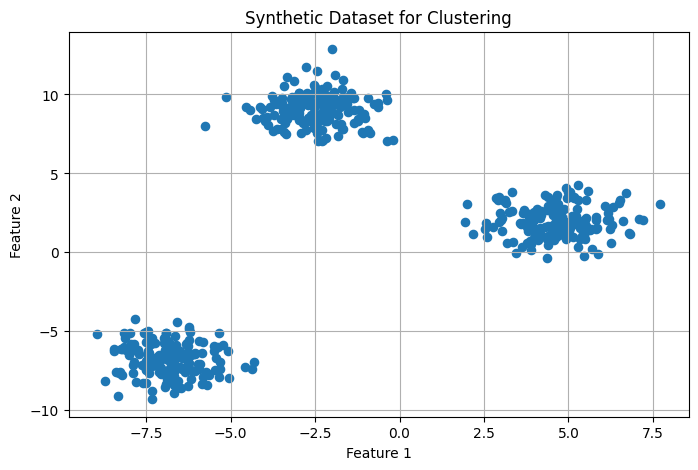

In [2]:
# Generate synthetic data containing three groups
X, y_true = make_blobs(
    n_samples=500,
    centers=3,
    cluster_std=1.0,
    random_state=42
)

data_df = pd.DataFrame(
    X,
    columns=["Feature 1", "Feature 2"]
)

print("Dataset shape:", data_df.shape)
display(data_df.head())

plt.figure(figsize=(8, 5))
plt.scatter(
    X[:, 0],
    X[:, 1],
    s=35
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Synthetic Dataset for Clustering")
plt.grid(True)
plt.show()

### How It Works

The `make_blobs()` function generates a synthetic dataset containing
observations around several centers.

The two features allow the observations to be visualized in a
two-dimensional scatter plot.

The variable `y_true` records the generated groups for demonstration
and evaluation purposes. It is not supplied to the clustering model
during training.

In real unsupervised learning tasks, the true group labels are often
unknown. Therefore, the discovered clusters must be evaluated using
appropriate metrics and domain knowledge.

## 2. K-Means Clustering

K-Means partitions observations into K clusters. Each cluster is
represented by a centroid, calculated as the mean of its observations.

The algorithm repeatedly performs two main operations:

1. Assign each observation to the nearest centroid.
2. Recalculate each centroid based on its assigned observations.

These steps continue until the assignments or centroids stabilize,
or until the iteration limit is reached.

### Important Parameters

- `n_clusters`: The number of clusters, K.
- `init`: The centroid initialization method.
- `n_init`: The number of independent initializations.
- `max_iter`: The maximum number of iterations.
- `random_state`: Controls reproducibility.

K-Means is efficient for many numerical datasets but can struggle
with irregularly shaped clusters, varying densities, and outliers.
Feature scaling is important when variables use different units.

In [3]:
kmeans = KMeans(
    n_clusters=3,
    init="k-means++",
    n_init=10,
    max_iter=300,
    random_state=42
)

kmeans_labels = kmeans.fit_predict(X)

print("Cluster labels:")
print(np.unique(kmeans_labels))

print("\nCluster sizes:")
print(pd.Series(kmeans_labels).value_counts().sort_index())

print("\nInertia:", round(kmeans.inertia_, 3))

Cluster labels:
[0 1 2]

Cluster sizes:
0    167
1    166
2    167
Name: count, dtype: int64

Inertia: 955.649


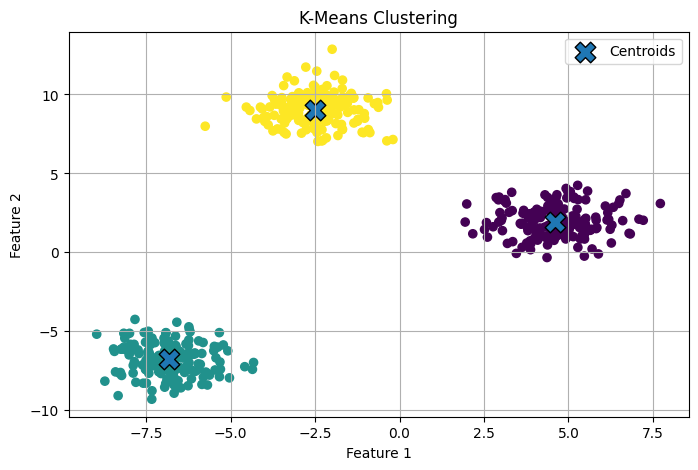

In [4]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=35
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker="X",
    s=220,
    edgecolors="black",
    label="Centroids"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("K-Means Clustering")
plt.legend()
plt.grid(True)
plt.show()

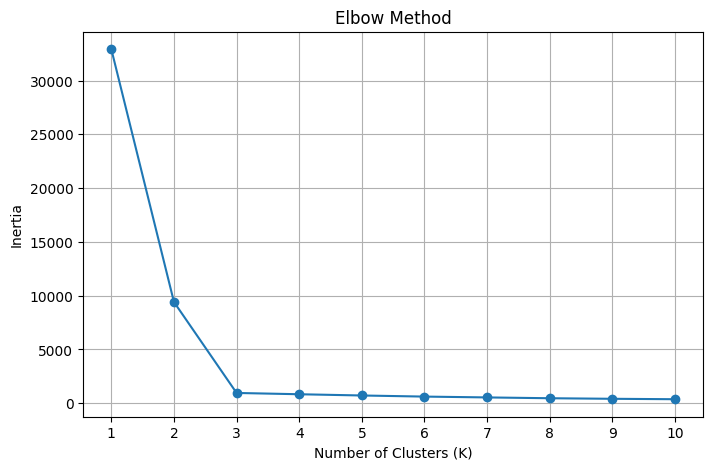

In [5]:
inertias = []
k_values = range(1, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )
    model.fit(X)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    inertias,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

### How It Works

The model assigns each observation to one of three clusters.
The centroid markers indicate the center of each learned cluster.

Inertia measures the sum of squared distances from observations to
their assigned centroids. It generally decreases as K increases.

The Elbow Method looks for a point where adding more clusters yields
smaller improvements in inertia.

The elbow is not always clear, and the best number of clusters cannot
be determined by inertia alone. Cluster interpretability and other
evaluation measures should also be considered.

## 3. Hierarchical Clustering

Hierarchical clustering builds a hierarchy of clusters based on
distances between observations or groups.

Agglomerative clustering is a bottom-up approach:

1. Start with each observation as an individual cluster.
2. Merge the two closest clusters.
3. Recalculate the distances between clusters.
4. Repeat until the desired grouping is obtained or all observations
   have been merged into one cluster.

### Linkage Methods

- `ward`: Merges clusters to minimize the increase in within-cluster
  variance.
- `complete`: Uses the maximum distance between observations in
  different clusters.
- `average`: Uses the average pairwise distance between clusters.
- `single`: Uses the minimum distance between clusters.

A dendrogram can display the sequence of merges. Hierarchical
clustering can be useful when the relationships between groups are
as important as the final cluster assignments.

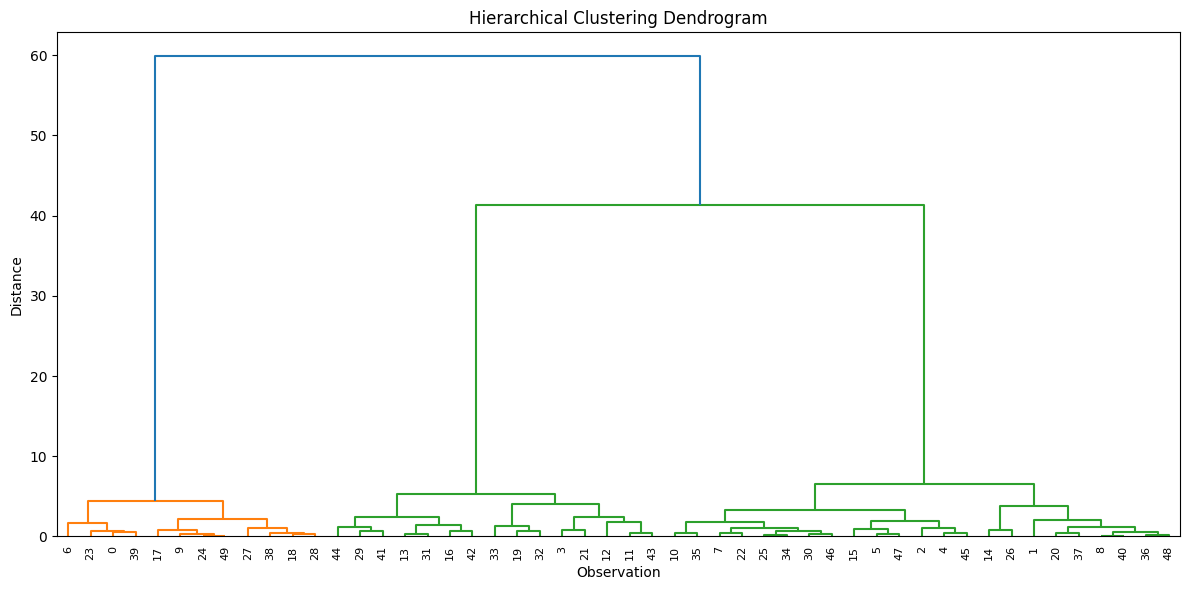

In [6]:
from scipy.cluster.hierarchy import linkage, dendrogram

# Use a smaller sample to keep the dendrogram readable
X_hier = X[:50]

Z = linkage(
    X_hier,
    method="ward"
)

plt.figure(figsize=(12, 6))

dendrogram(
    Z,
    leaf_rotation=90,
    leaf_font_size=8
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Observation")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()

Cluster sizes:
0    167
1    166
2    167
Name: count, dtype: int64


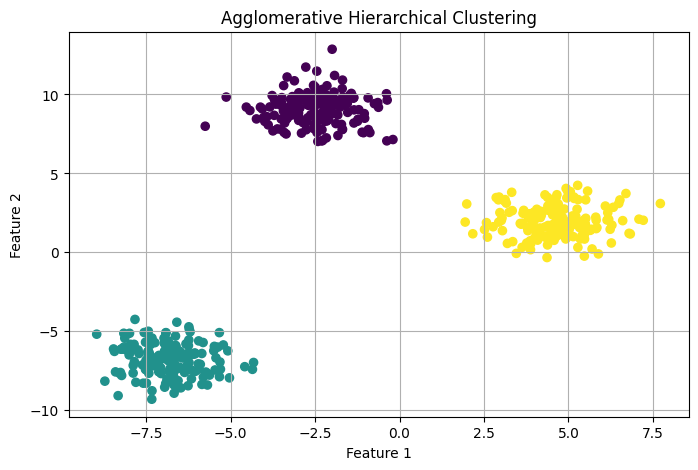

In [7]:
hierarchical = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

hierarchical_labels = hierarchical.fit_predict(X)

print("Cluster sizes:")
print(
    pd.Series(hierarchical_labels)
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=hierarchical_labels,
    cmap="viridis",
    s=35
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Agglomerative Hierarchical Clustering")
plt.grid(True)
plt.show()

### How It Works

The dendrogram displays the order in which observations or clusters
are merged. The vertical axis represents the distance at which
merges occur.

A horizontal cut across the dendrogram can be used to obtain a
chosen number of clusters.

The `AgglomerativeClustering` implementation produces cluster labels
for the selected number of clusters.

The dendrogram uses only 50 observations to make the visualization
easier to read, whereas the clustering example fits all observations
in X.

Hierarchical clustering can be computationally expensive for large
datasets. The linkage method also affects the resulting hierarchy.

## 4. Density-Based Clustering with DBSCAN

DBSCAN stands for Density-Based Spatial Clustering of Applications
with Noise.

Unlike K-Means, DBSCAN does not require the number of clusters to
be specified in advance. It identifies clusters based on regions
with sufficiently high point density.

### Important Parameters

- `eps`: The neighborhood radius used to identify nearby points.
- `min_samples`: The minimum number of nearby samples needed to
  identify a core point.

DBSCAN can identify clusters with irregular shapes and label
observations that do not belong to any cluster as noise.

In scikit-learn, noise observations receive the label -1.

DBSCAN is sensitive to parameter choices and may have difficulty
when different clusters have very different densities.

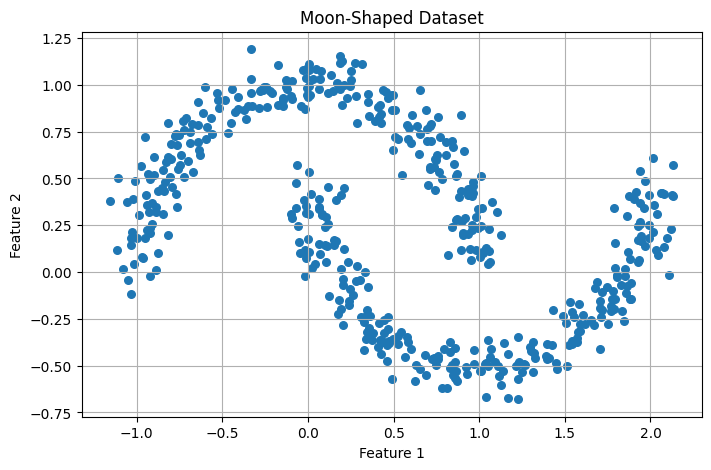

In [8]:
X_moons, y_moons = make_moons(
    n_samples=500,
    noise=0.08,
    random_state=42
)

plt.figure(figsize=(8, 5))

plt.scatter(
    X_moons[:, 0],
    X_moons[:, 1],
    s=30
)

plt.title("Moon-Shaped Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.grid(True)
plt.show()

In [9]:
dbscan = DBSCAN(
    eps=0.2,
    min_samples=5
)

dbscan_labels = dbscan.fit_predict(X_moons)

unique_labels = np.unique(dbscan_labels)
n_clusters = len(set(dbscan_labels) - {-1})
n_noise = np.sum(dbscan_labels == -1)

print("Cluster labels:", unique_labels)
print("Number of clusters:", n_clusters)
print("Number of noise points:", n_noise)

Cluster labels: [0 1]
Number of clusters: 2
Number of noise points: 0


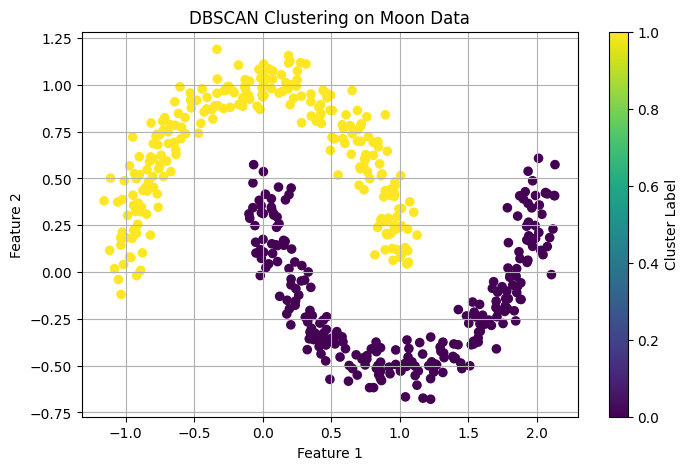

In [10]:
plt.figure(figsize=(8, 5))

scatter = plt.scatter(
    X_moons[:, 0],
    X_moons[:, 1],
    c=dbscan_labels,
    cmap="viridis",
    s=35
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("DBSCAN Clustering on Moon Data")
plt.colorbar(scatter, label="Cluster Label")
plt.grid(True)
plt.show()

### How It Works

DBSCAN identifies dense regions and connects nearby core points
to form clusters. Points that cannot be assigned to a dense region
are classified as noise.

The moon-shaped dataset demonstrates a case in which clusters are
not naturally represented by circular groups around centroids.

Unlike K-Means, DBSCAN can often recover these curved shapes because
it relies on local density rather than distance to a centroid.

The parameters `eps` and `min_samples` strongly influence the result.
If `eps` is too small, many points may be classified as noise.
If it is too large, separate groups may merge.

## 5. Cluster Evaluation Metrics

Clustering evaluation helps assess how well observations are grouped.

### Silhouette Score

Measures how similar each observation is to its own cluster compared
with other clusters. Scores range from -1 to 1. Higher values generally
indicate better separation.

### Davies-Bouldin Index

Measures the similarity between clusters based on within-cluster
dispersion and separation. Lower values generally indicate better
separation.

### Calinski-Harabasz Index

Compares between-cluster dispersion with within-cluster dispersion.
Higher values generally indicate better-defined clusters.

### Adjusted Rand Index (ARI)

ARI compares predicted cluster assignments with known reference labels.
It is useful when ground-truth labels are available, but ordinary
unsupervised clustering does not require such labels.

Not all metrics apply to every clustering output. For example,
silhouette scoring requires at least two clusters and fewer clusters
than the number of observations.

In [11]:
kmeans_eval = KMeans(
    n_clusters=3,
    n_init=10,
    random_state=42
)

labels_eval = kmeans_eval.fit_predict(X)

print("Silhouette Score:",
      round(silhouette_score(X, labels_eval), 4))

print("Davies-Bouldin Index:",
      round(davies_bouldin_score(X, labels_eval), 4))

print("Calinski-Harabasz Index:",
      round(calinski_harabasz_score(X, labels_eval), 4))

print("Adjusted Rand Index:",
      round(adjusted_rand_score(y_true, labels_eval), 4))

Silhouette Score: 0.8438
Davies-Bouldin Index: 0.2215
Calinski-Harabasz Index: 8309.6076
Adjusted Rand Index: 1.0


In [12]:
kmeans_moons = KMeans(
    n_clusters=2,
    n_init=10,
    random_state=42
)

kmeans_moon_labels = kmeans_moons.fit_predict(X_moons)

dbscan_moon_labels = DBSCAN(
    eps=0.2,
    min_samples=5
).fit_predict(X_moons)

def evaluate_clusters(X_data, labels, model_name):
    labels = np.asarray(labels)
    non_noise = labels != -1

    # Silhouette is only defined for at least two clusters
    # and fewer clusters than samples.
    valid_labels = labels[non_noise]
    valid_data = X_data[non_noise]
    n_clusters = len(np.unique(valid_labels))

    result = {
        "Model": model_name,
        "Number of Clusters": n_clusters,
        "Noise Points": int(np.sum(labels == -1)),
        "Silhouette Score": np.nan
    }

    if 2 <= n_clusters < len(valid_labels):
        result["Silhouette Score"] = silhouette_score(
            valid_data,
            valid_labels
        )

    return result

metrics_comparison = pd.DataFrame([
    evaluate_clusters(
        X_moons,
        kmeans_moon_labels,
        "K-Means"
    ),
    evaluate_clusters(
        X_moons,
        dbscan_moon_labels,
        "DBSCAN"
    )
])

display(metrics_comparison)

,Model,Number of Clusters,Noise Points,Silhouette Score
0,K-Means,2,0,0.485759
1,DBSCAN,2,0,0.330576


### How It Works

The evaluation metrics provide different perspectives on cluster
quality.

Silhouette measures cohesion and separation. Davies-Bouldin and
Calinski-Harabasz provide additional measures based on cluster
dispersion.

The Adjusted Rand Index compares clustering results with known
synthetic labels. It is used here because the synthetic dataset
provides reference labels for evaluation.

For DBSCAN, noise observations are excluded from the silhouette
calculation in the comparison. This makes the calculation explicit,
but it also means the score does not evaluate how well the model
handled those noise observations.

Metrics should not be interpreted in isolation. A good score on one
dataset does not guarantee that the same algorithm will work well
on another dataset.

## 6. Choosing the Right Clustering Algorithm

Different clustering algorithms make different assumptions about
the structure of the data.

### K-Means

- Requires the number of clusters to be specified.
- Works well for many compact, centroid-based groups.
- Can be affected by outliers and feature scales.

### Hierarchical Clustering

- Builds a hierarchy of groups.
- Supports different linkage methods.
- Can be computationally expensive for large datasets.

### DBSCAN

- Finds dense regions and can identify noise.
- Does not require the number of clusters to be specified.
- Can struggle when clusters have substantially different densities.

Algorithm selection should consider the data distribution, the
presence of noise, the size of the dataset, computational resources,
and the purpose of the analysis.

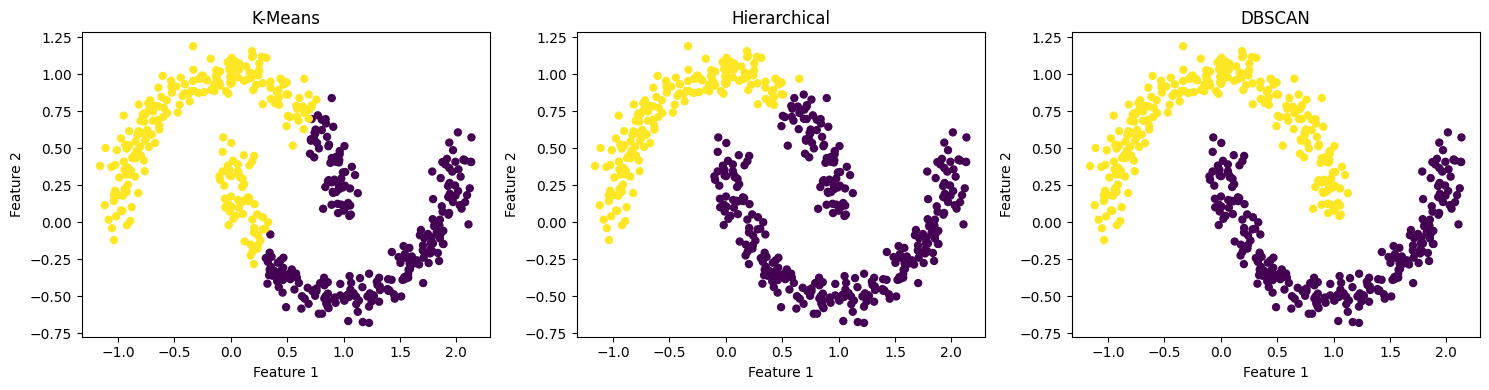

In [13]:
# K-Means
kmeans_model = KMeans(
    n_clusters=2,
    n_init=10,
    random_state=42
)
labels_kmeans = kmeans_model.fit_predict(X_moons)

# Hierarchical clustering
hierarchical_model = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward"
)
labels_hierarchical = hierarchical_model.fit_predict(X_moons)

# DBSCAN
dbscan_model = DBSCAN(
    eps=0.2,
    min_samples=5
)
labels_dbscan = dbscan_model.fit_predict(X_moons)

# Plot the results
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

results = [
    ("K-Means", labels_kmeans),
    ("Hierarchical", labels_hierarchical),
    ("DBSCAN", labels_dbscan)
]

for ax, (name, labels) in zip(axes, results):
    ax.scatter(
        X_moons[:, 0],
        X_moons[:, 1],
        c=labels,
        cmap="viridis",
        s=25
    )
    ax.set_title(name)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

plt.tight_layout()
plt.show()

### How It Works

The three algorithms are applied to the same moon-shaped dataset.

K-Means assigns observations to the nearest centroid. Hierarchical
clustering builds groups using a linkage rule. DBSCAN forms groups
from sufficiently dense regions and may identify noise observations.

The visual comparison illustrates how algorithm assumptions affect
the shape of the discovered clusters.

For this dataset, K-Means may struggle to represent the curved groups,
whereas DBSCAN can often identify the two moon-shaped regions.

The results depend on parameter settings and should be interpreted
alongside numerical evaluation and the purpose of the analysis.

## 7. Advanced Clustering Techniques

Some datasets contain many features, which can make clustering
more difficult to visualize and computationally expensive.

Two useful techniques are:

### Principal Components Analysis (PCA)

PCA transforms numerical features into principal components that
capture variation in the data. It can reduce dimensionality before
clustering and help visualize high-dimensional observations.

### Gaussian Mixture Models (GMM)

A Gaussian Mixture Model represents the data as a mixture of
probability distributions. It estimates the probability that each
observation belongs to each component.

Unlike K-Means, GMM can model clusters with different covariance
structures and provides probabilistic membership estimates.

Combining PCA and GMM can provide a practical workflow for exploring
high-dimensional data. However, reducing dimensions can remove
information, and GMM relies on assumptions about the data distribution.

In [14]:
# Create a high-dimensional synthetic dataset
X_high, y_high = make_blobs(
    n_samples=600,
    centers=3,
    n_features=10,
    cluster_std=2.0,
    random_state=42
)

# Standardize the data
scaler = StandardScaler()
X_high_scaled = scaler.fit_transform(X_high)

# Reduce the data to two principal components
pca = PCA(n_components=2)
X_high_pca = pca.fit_transform(X_high_scaled)

print("Original shape:", X_high_scaled.shape)
print("Reduced shape:", X_high_pca.shape)

print(
    "Explained variance by two components:",
    round(pca.explained_variance_ratio_.sum(), 4)
)

Original shape: (600, 10)
Reduced shape: (600, 2)
Explained variance by two components: 0.7993


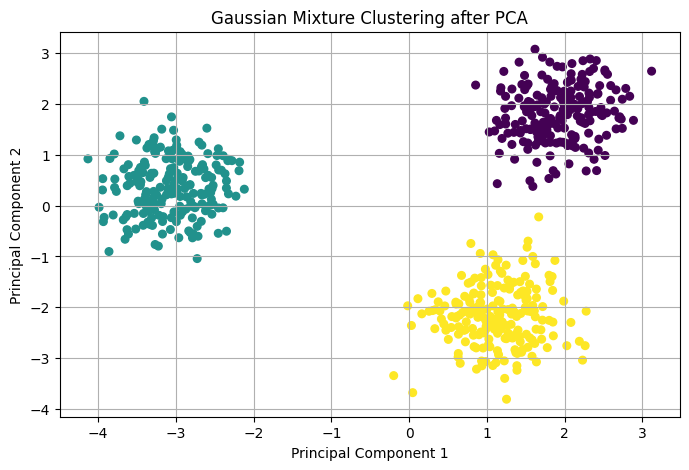

GMM BIC: 3161.71

Membership probabilities for the first five observations:


,Component 1,Component 2,Component 3
0,1.0,0.0,0.0
1,1.0,0.0,0.0
2,0.0,1.0,0.0
3,0.0,0.0,1.0
4,0.0,1.0,0.0


In [15]:
gmm = GaussianMixture(
    n_components=3,
    covariance_type="full",
    random_state=42,
    n_init=5
)

gmm_labels = gmm.fit_predict(X_high_pca)
gmm_probabilities = gmm.predict_proba(X_high_pca)

plt.figure(figsize=(8, 5))

plt.scatter(
    X_high_pca[:, 0],
    X_high_pca[:, 1],
    c=gmm_labels,
    cmap="viridis",
    s=30
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Gaussian Mixture Clustering after PCA")
plt.grid(True)
plt.show()

print("GMM BIC:", round(gmm.bic(X_high_pca), 3))

print("\nMembership probabilities for the first five observations:")
display(
    pd.DataFrame(
        gmm_probabilities[:5],
        columns=[
            f"Component {i + 1}"
            for i in range(gmm.n_components)
        ]
    ).round(3)
)

### How It Works

The high-dimensional dataset contains ten features. StandardScaler
makes the features comparable before PCA is applied.

PCA projects the data onto two principal components, allowing the
observations to be displayed in a two-dimensional plot.

The Gaussian Mixture Model then assigns observations to components
and estimates membership probabilities.

The Bayesian Information Criterion (BIC) provides a way to compare
candidate mixture models. When comparing models fitted to the same
data, a lower BIC is generally preferred.

This is a demonstration of a PCA-plus-GMM workflow. The number of
components is set to three for this example; it should be selected
through model comparison when the true grouping is unknown.

In [16]:
iris = load_iris()

X_iris = iris.data
y_iris = iris.target

# Scale the features
iris_scaler = StandardScaler()
X_iris_scaled = iris_scaler.fit_transform(X_iris)

# Fit K-Means
iris_kmeans = KMeans(
    n_clusters=3,
    n_init=10,
    random_state=42
)

iris_clusters = iris_kmeans.fit_predict(X_iris_scaled)

print("Cluster sizes:")
print(pd.Series(iris_clusters).value_counts().sort_index())

print(
    "\nSilhouette Score:",
    round(silhouette_score(X_iris_scaled, iris_clusters), 4)
)

print(
    "Adjusted Rand Index:",
    round(adjusted_rand_score(y_iris, iris_clusters), 4)
)

Cluster sizes:
0    53
1    50
2    47
Name: count, dtype: int64

Silhouette Score: 0.4599
Adjusted Rand Index: 0.6201


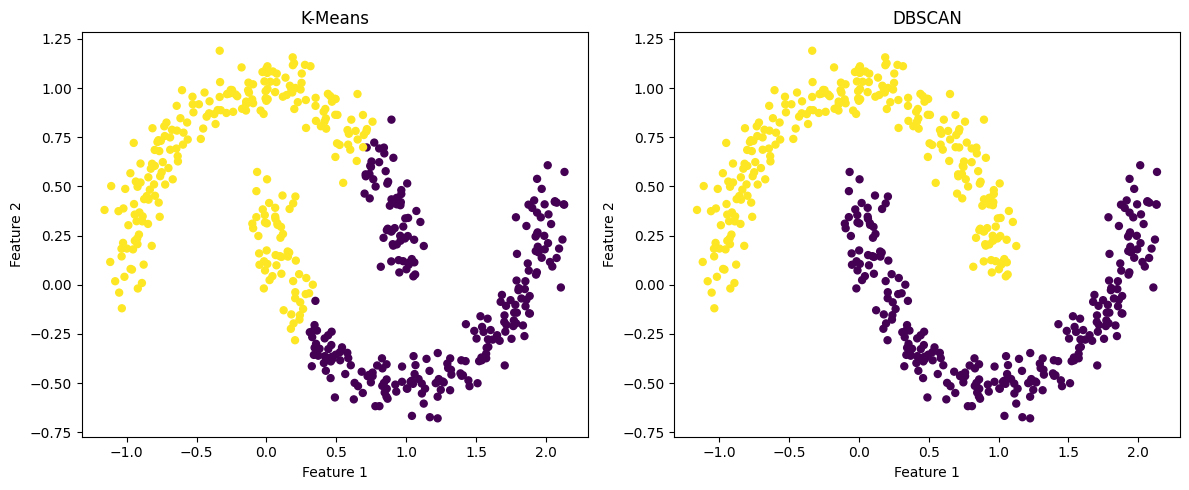

K-Means ARI: 0.2648
DBSCAN ARI: 1.0


In [17]:
# Compare both algorithms using the moon dataset
exercise_kmeans = KMeans(
    n_clusters=2,
    n_init=10,
    random_state=42
)

exercise_dbscan = DBSCAN(
    eps=0.2,
    min_samples=5
)

labels_km = exercise_kmeans.fit_predict(X_moons)
labels_db = exercise_dbscan.fit_predict(X_moons)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(
    X_moons[:, 0],
    X_moons[:, 1],
    c=labels_km,
    cmap="viridis",
    s=25
)
axes[0].set_title("K-Means")

axes[1].scatter(
    X_moons[:, 0],
    X_moons[:, 1],
    c=labels_db,
    cmap="viridis",
    s=25
)
axes[1].set_title("DBSCAN")

for ax in axes:
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

plt.tight_layout()
plt.show()

print("K-Means ARI:", round(adjusted_rand_score(y_moons, labels_km), 4))
print("DBSCAN ARI:", round(adjusted_rand_score(y_moons, labels_db), 4))

Reduced dataset shape: (600, 2)
GMM BIC: 3161.71


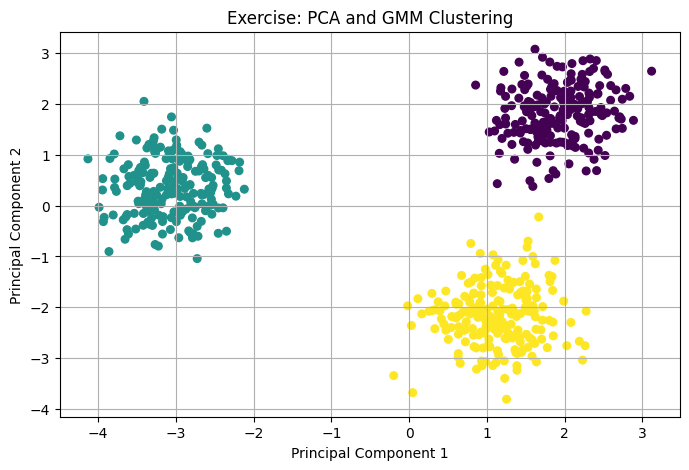

In [18]:
# Use the high-dimensional dataset created earlier
pca_exercise = PCA(n_components=2)
X_reduced = pca_exercise.fit_transform(X_high_scaled)

gmm_exercise = GaussianMixture(
    n_components=3,
    covariance_type="full",
    random_state=42,
    n_init=5
)

labels_gmm = gmm_exercise.fit_predict(X_reduced)

print("Reduced dataset shape:", X_reduced.shape)
print("GMM BIC:", round(gmm_exercise.bic(X_reduced), 3))

plt.figure(figsize=(8, 5))

plt.scatter(
    X_reduced[:, 0],
    X_reduced[:, 1],
    c=labels_gmm,
    cmap="viridis",
    s=30
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Exercise: PCA and GMM Clustering")
plt.grid(True)
plt.show()

## 8. Summary

Chapter 10 introduced clustering techniques for discovering natural
groupings in unlabeled data.

The main concepts covered were:

1. **Introduction to clustering:** Clustering identifies groups of
   similar observations without requiring target labels.
2. **K-Means:** Groups observations around centroids and requires
   the number of clusters to be specified.
3. **Hierarchical clustering:** Builds a hierarchy of clusters that
   can be explored using a dendrogram.
4. **DBSCAN:** Finds dense regions, can identify irregularly shaped
   clusters, and can label noise observations.
5. **Cluster evaluation:** Silhouette score, Davies-Bouldin index,
   Calinski-Harabasz index, and Adjusted Rand Index provide different
   perspectives on clustering quality.
6. **Algorithm selection:** The appropriate algorithm depends on
   data structure, noise, scale, and the goal of the analysis.
7. **Advanced techniques:** PCA can reduce dimensionality, while
   Gaussian Mixture Models provide probabilistic cluster assignments.

The practical exercises applied these methods to the Iris dataset,
moon-shaped data, and high-dimensional synthetic data.

No clustering algorithm is universally best. Results should be
evaluated using suitable metrics and interpreted in the context of
the underlying problem.

## References

Sukup, J. (2025).
scikit-learn Cookbook, Third Edition.
Packt Publishing.

Official repository:
https://github.com/PacktPublishing/scikit-learn-Cookbook-Third-Edition

## Reproduction Notes

This notebook follows the chapter structure and clustering topics
from Chapter 10.

The examples demonstrate K-Means, hierarchical clustering, DBSCAN,
cluster evaluation metrics, and advanced clustering with PCA and GMM.

For strict code reproduction, compare the notebook with the original
Chapter 10 recipes in the official repository. Additional examples
or parameter changes should be identified as adaptations rather
than exact reproductions.